# Multimodal d-prime Analysis

This notebook computes d-prime discriminability for:
- E: Electrophysiology features
- M: Morphology features
- ME: Combined morphology + electrophysiology features

And generates multimodal comparison plots.

## Imports and Setup

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.ensemble import RandomForestClassifier
import scipy.stats as stats
import scikit_posthocs as sp
from statannotations.Annotator import Annotator
import cluster_pairs as cp
import sys
sys.path.append('/root/capsule/code/figures')
from core_utils import get_seaad_colors, get_tx_order

## Configuration and Paths

In [2]:
# Output directory
OUT_DIR = Path('/root/capsule/scratch/20260807/dprime')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')
METADATA_PATH = DATA_ROOT / 'human' / 'metadata' / '20260807' / 'human_metadata.csv'
EPHYS_FEATURES_PATH = DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features_imputed.csv'
MORPHO_FEATURES_PATH = DATA_ROOT / 'human' / 'morphology' / 'dendrite' / '20260712' / 'RawFeatureWide_imputed.csv'
TTYPE_LAYER_DICT_PATH = DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'
L23_TTYPE_RENAME_PATH = DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
MODALITY_COLOR_PATH = DATA_ROOT / 'colors' / 'modality_colors.json'

# Analysis parameters
MIN_CLASS_SIZE = 3  # Minimum cells per type for d-prime calculation
HIERARCHICAL_COLUMNS = {
    'class_col': 'class_label_Hierarchical',
    'subclass_col': 'subclass_label_Hierarchical',
    'cluster_col': 'cluster_label_Hierarchical'
}

In [3]:
# Load formatting dictionaries
with open(TTYPE_LAYER_DICT_PATH, 'r') as f:
    ttype_to_layer_dict = json.load(f)

with open(L23_TTYPE_RENAME_PATH, 'r') as f:
    L23_ttype_rename_dict = json.load(f)

with open(MODALITY_COLOR_PATH, 'r') as f:
    modality_color_dict = json.load(f)

# Load metadata
metadata = pd.read_csv(METADATA_PATH, encoding='latin1')
metadata = metadata.rename(columns={
    'cell_id': 'specimen_id',
    HIERARCHICAL_COLUMNS['cluster_col']: 't_type',
    HIERARCHICAL_COLUMNS['subclass_col']: 'subclass_label'
})

# Clean and format metadata
# Remove ME cells 
metadata = metadata[~metadata['t_type'].str.contains( r'L5 ET_ME|L5 ET\(ME\)', na=False)]
metadata['t_type'] = metadata['t_type'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata['t_type'].map(ttype_to_layer_dict)

# Create layer_subclass column (split L2/3 IT into L2 IT and L3 IT based on layer)
metadata['layer_subclass'] = metadata.apply(
    lambda row: 'L2 IT' if row['layer'] == 'Layer 2'
                else ('L3 IT' if row['layer'] == 'Layer 3'
                      else row['subclass_label']),
    axis=1
)

metadata = metadata.set_index('specimen_id')
metadata = metadata[['t_type', 'subclass_label', 'layer_subclass', 'layer']]

print(f"Loaded metadata for {len(metadata)} cells")
print(f"Unique layers: {metadata['layer'].unique()}")
print(f"Unique subclasses: {metadata['subclass_label'].unique()}")

Loaded metadata for 1504 cells
Unique layers: ['Layer 5' 'Layer 2' 'Layer 4' 'Layer 3' 'Layer 6']
Unique subclasses: ['L5/6 NP' 'L2/3 IT' 'L4 IT' 'L5 IT' 'L6 IT Car3' 'L6 IT' 'L6 CT' 'L5 ET'
 'L6b']


## Load Feature Data

In [4]:
# Load electrophysiology features
ephys_features = pd.read_csv(EPHYS_FEATURES_PATH, index_col='specimen_id')
ephys_feature_names = [c for c in ephys_features.columns if not c.endswith('_label_Hierarchical')]
ephys_features = ephys_features[ephys_feature_names]
print(f"Loaded {len(ephys_feature_names)} electrophysiology features for {len(ephys_features)} cells")

# Load morphology features
morpho_features = pd.read_csv(MORPHO_FEATURES_PATH, index_col='specimen_id')
morpho_feature_names = morpho_features.columns.tolist()
print(f"Loaded {len(morpho_feature_names)} morphology features for {len(morpho_features)} cells")

# Merge features with metadata
e_data = metadata.merge(ephys_features, how='inner', left_index=True, right_index=True)
m_data = metadata.merge(morpho_features, how='inner', left_index=True, right_index=True)

# Combined morpho-electric data
me_features = morpho_features.merge(ephys_features, how='inner', left_index=True, right_index=True)
me_feature_names = me_features.columns.tolist()
me_data = metadata.merge(me_features, how='inner', left_index=True, right_index=True)

print(f"\nE data: {len(e_data)} cells")
print(f"M data: {len(m_data)} cells")
print(f"ME data: {len(me_data)} cells with {len(me_feature_names)} combined features")

Loaded 25 electrophysiology features for 1044 cells
Loaded 52 morphology features for 327 cells

E data: 1044 cells
M data: 322 cells
ME data: 283 cells with 77 combined features


## Load Colors and Ordering

In [5]:
# # Get SEAAD colors
# color_dict = get_seaad_colors()

# Get transcriptomic ordering
ttype_order, subclass_order = get_tx_order()
layer_subclass_order = ['L2 IT'] + [l.replace('L2/3 IT', 'L3 IT') for l in subclass_order]

# # Plotting parameters
# matrix_colormap = 'rocket'

## Helper Functions

In [6]:
def compute_layer_dprime(data, features, min_class_size=MIN_CLASS_SIZE):
    """Compute pairwise d-prime for all t-types within each layer."""
    layer_dprime_dfs = {}
    layer_dprime_records = {}
    layer_dprime_avgs = {}
    layer_dprime_stds = {}
    layer_lost_ttypes = []
    
    for layer in data['layer'].unique():
        this_data = data[data['layer'] == layer]
        all_ttypes = set(this_data['t_type'].unique())
        
        # Filter types with sufficient cells
        counts = this_data['t_type'].value_counts()
        this_data = this_data[this_data['t_type'].map(counts) > min_class_size]
        
        # Track lost types
        remaining_ttypes = set(this_data['t_type'].unique())
        lost_ttypes = all_ttypes - remaining_ttypes
        if len(lost_ttypes) > 0:
            layer_lost_ttypes.append(counts[counts.values <= min_class_size].to_dict())
        
        if len(this_data) > 0 and len(this_data['t_type'].unique()) > 1:
            # Compute pairwise d-prime
            clf = RandomForestClassifier(class_weight='balanced_subsample', random_state=42)
            dprime_df, records = cp.pairwise_cluster_distances(
                clf, this_data, features, cv=min_class_size, 
                cluster_label='t_type', details=True
            )
            dprime_df = dprime_df.abs()
            
            # Compute statistics
            dprime_vals = dprime_df.values[np.triu_indices_from(dprime_df, k=1)]
            avg_dprime = dprime_vals.mean()
            std_dprime = dprime_vals.std()
            
            layer_dprime_dfs[layer] = dprime_df
            layer_dprime_records[layer] = records
            layer_dprime_avgs[layer] = avg_dprime
            layer_dprime_stds[layer] = std_dprime
    
    return layer_dprime_dfs, layer_dprime_records, layer_dprime_avgs, layer_dprime_stds, layer_lost_ttypes


def compute_subclass_dprime(data, features, min_class_size=MIN_CLASS_SIZE):
    """Compute pairwise d-prime for all t-types within each subclass."""
    subclass_dprime_dfs = {}
    subclass_dprime_records = {}
    subclass_dprime_avgs = {}
    subclass_dprime_stds = {}
    subclass_lost_ttypes = []
    
    for subclass in data['subclass_label'].unique():
        this_data = data[data['subclass_label'] == subclass]
        all_ttypes = set(this_data['t_type'].unique())
        
        if len(all_ttypes) > 1:
            # Filter types with sufficient cells
            counts = this_data['t_type'].value_counts()
            this_data = this_data[this_data['t_type'].map(counts) > min_class_size]
            
            # Track lost types
            remaining_ttypes = set(this_data['t_type'].unique())
            lost_ttypes = all_ttypes - remaining_ttypes
            if len(lost_ttypes) > 0:
                subclass_lost_ttypes.append(counts[counts.values <= min_class_size].to_dict())
            
            if len(this_data) > 0 and len(this_data['t_type'].unique()) > 1:
                # Compute pairwise d-prime
                clf = RandomForestClassifier(class_weight='balanced_subsample', random_state=42)
                dprime_df, records = cp.pairwise_cluster_distances(
                    clf, this_data, features, cv=min_class_size,
                    cluster_label='t_type', details=True
                )
                dprime_df = dprime_df.abs()
                
                # Compute statistics
                dprime_vals = dprime_df.values[np.triu_indices_from(dprime_df, k=1)]
                avg_dprime = dprime_vals.mean()
                std_dprime = dprime_vals.std()
                
                subclass_dprime_dfs[subclass] = dprime_df
                subclass_dprime_records[subclass] = records
                subclass_dprime_avgs[subclass] = avg_dprime
                subclass_dprime_stds[subclass] = std_dprime
    
    return subclass_dprime_dfs, subclass_dprime_records, subclass_dprime_avgs, subclass_dprime_stds, subclass_lost_ttypes


def create_dprime_long_df(dprime_dfs, metadata, groupby_col):
    """Convert d-prime matrices to long format with subclass annotations."""
    all_vals = []
    for group, df in dprime_dfs.items():
        rows, cols = np.triu_indices_from(df, k=1)
        
        for r, c in zip(rows, cols):
            c1 = df.index[r]
            c2 = df.columns[c]
            
            s1 = metadata.loc[metadata['t_type'] == c1, 'subclass_label'].unique()[0]
            s2 = metadata.loc[metadata['t_type'] == c2, 'subclass_label'].unique()[0]
            
            all_vals.append({
                groupby_col: group,
                'dprime': df.iloc[r, c],
                'cluster_1': c1,
                'cluster_2': c2,
                'subclass_1': s1,
                'subclass_2': s2,
                'same_subclass': s1 == s2,
            })
    
    return pd.DataFrame(all_vals).sort_values(by=[groupby_col, 'dprime'])

## Compute E (Electrophysiology) d-prime

In [7]:
print("Computing E (electrophysiology) d-prime...")

# By layer
e_layer_dfs, e_layer_records, e_layer_avgs, e_layer_stds, e_layer_lost = compute_layer_dprime(
    e_data, ephys_feature_names
)
e_layer_long = create_dprime_long_df(e_layer_dfs, metadata, 'layer')

# By subclass
e_subclass_dfs, e_subclass_records, e_subclass_avgs, e_subclass_stds, e_subclass_lost = compute_subclass_dprime(
    e_data, ephys_feature_names
)
e_subclass_long = create_dprime_long_df(e_subclass_dfs, metadata, 'subclass_label')

print(f"E layer d-prime computed for {len(e_layer_dfs)} layers")
print(f"E subclass d-prime computed for {len(e_subclass_dfs)} subclasses")

Computing E (electrophysiology) d-prime...


/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the numb

E layer d-prime computed for 5 layers
E subclass d-prime computed for 8 subclasses


## Compute M (Morphology) d-prime

In [8]:
print("Computing M (morphology) d-prime...")

# By layer
m_layer_dfs, m_layer_records, m_layer_avgs, m_layer_stds, m_layer_lost = compute_layer_dprime(
    m_data, morpho_feature_names
)
m_layer_long = create_dprime_long_df(m_layer_dfs, metadata, 'layer')

# By subclass
m_subclass_dfs, m_subclass_records, m_subclass_avgs, m_subclass_stds, m_subclass_lost = compute_subclass_dprime(
    m_data, morpho_feature_names
)
m_subclass_long = create_dprime_long_df(m_subclass_dfs, metadata, 'subclass_label')

print(f"M layer d-prime computed for {len(m_layer_dfs)} layers")
print(f"M subclass d-prime computed for {len(m_subclass_dfs)} subclasses")

Computing M (morphology) d-prime...


/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the numb

M layer d-prime computed for 5 layers
M subclass d-prime computed for 5 subclasses


## Compute ME (Morpho-Electric) d-prime

In [9]:
print("Computing ME (morpho-electric) d-prime...")

# By layer
me_layer_dfs, me_layer_records, me_layer_avgs, me_layer_stds, me_layer_lost = compute_layer_dprime(
    me_data, me_feature_names
)
me_layer_long = create_dprime_long_df(me_layer_dfs, metadata, 'layer')

# By subclass
me_subclass_dfs, me_subclass_records, me_subclass_avgs, me_subclass_stds, me_subclass_lost = compute_subclass_dprime(
    me_data, me_feature_names
)
me_subclass_long = create_dprime_long_df(me_subclass_dfs, metadata, 'subclass_label')

print(f"ME layer d-prime computed for {len(me_layer_dfs)} layers")
print(f"ME subclass d-prime computed for {len(me_subclass_dfs)} subclasses")

Computing ME (morpho-electric) d-prime...


/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the numb

ME layer d-prime computed for 5 layers
ME subclass d-prime computed for 4 subclasses


## Save CSV Files

In [10]:
# Save E data
e_layer_long.to_csv(OUT_DIR / 'dprime_layer_E.csv', index=False)
e_subclass_long.to_csv(OUT_DIR / 'dprime_subclass_E.csv', index=False)

# Save M data
m_layer_long.to_csv(OUT_DIR / 'dprime_layer_M.csv', index=False)
m_subclass_long.to_csv(OUT_DIR / 'dprime_subclass_M.csv', index=False)

# Save ME data
me_layer_long.to_csv(OUT_DIR / 'dprime_layer_ME.csv', index=False)
me_subclass_long.to_csv(OUT_DIR / 'dprime_subclass_ME.csv', index=False)

print("CSV files saved:")
print(f"  - dprime_layer_E.csv ({len(e_layer_long)} rows)")
print(f"  - dprime_subclass_E.csv ({len(e_subclass_long)} rows)")
print(f"  - dprime_layer_M.csv ({len(m_layer_long)} rows)")
print(f"  - dprime_subclass_M.csv ({len(m_subclass_long)} rows)")
print(f"  - dprime_layer_ME.csv ({len(me_layer_long)} rows)")
print(f"  - dprime_subclass_ME.csv ({len(me_subclass_long)} rows)")

CSV files saved:
  - dprime_layer_E.csv (110 rows)
  - dprime_subclass_E.csv (75 rows)
  - dprime_layer_M.csv (46 rows)
  - dprime_subclass_M.csv (43 rows)
  - dprime_layer_ME.csv (36 rows)
  - dprime_subclass_ME.csv (38 rows)


## Multimodal Plots - By Layer

/tmp/ipykernel_44704/2544707107.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_44704/2544707107.py:16: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


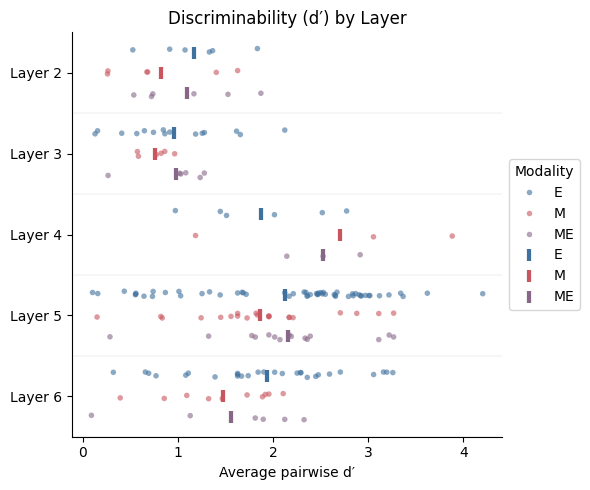

Saved: multimodal_dprime_pairwise_avg_by_layer.pdf


In [11]:
# Combine E, M, ME data for layer comparison
e_layer_long['modality'] = 'E'
m_layer_long['modality'] = 'M'
me_layer_long['modality'] = 'ME'

data_layer = pd.concat([e_layer_long, m_layer_long, me_layer_long])
data_layer.to_csv(OUT_DIR / 'multimodal_dprime_pairwise_avg_by_layer.csv', index=False)

# Create plot
fig, ax = plt.subplots(figsize=(6, 5))

sns.stripplot(
    data=data_layer, x='dprime', y='layer', hue='modality',
    size=4, jitter=True, alpha=0.6, dodge=True, palette=modality_color_dict
)
sns.pointplot(
    data=data_layer, x='dprime', y='layer', hue='modality',
    dodge=0.5, join=False, errorbar=None, markers='|', scale=1.5, palette=modality_color_dict
)

# Add horizontal separators
for i in range(len(data_layer['layer'].unique())):
    ax.axhline(y=i + 0.5, color='gray', lw=0.25, alpha=0.4)

sns.despine(top=True, right=True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Modality')
plt.xlabel("Average pairwise d′")
plt.ylabel("")
plt.title("Discriminability (d′) by Layer")
plt.tight_layout()
plt.savefig(OUT_DIR / 'multimodal_dprime_pairwise_avg_by_layer.pdf', dpi=600)
plt.show()

print("Saved: multimodal_dprime_pairwise_avg_by_layer.pdf")

## Multimodal Plots - By Layer (with same_subclass marker)

/tmp/ipykernel_44704/905795361.py:12: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_44704/905795361.py:12: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


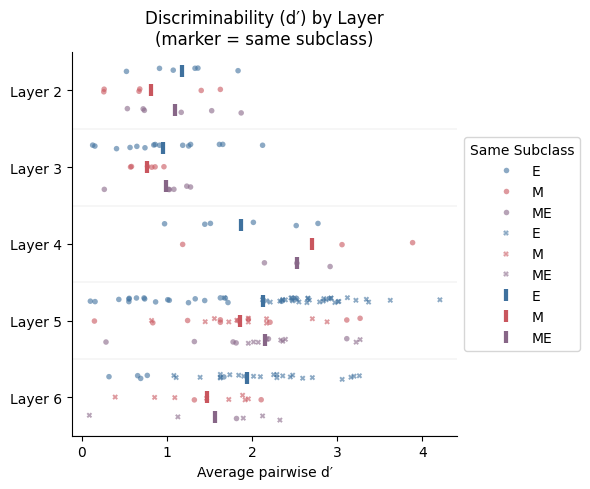

Saved: multimodal_dprime_pairwise_avg_by_layer_mark_same_subclass.pdf


In [12]:
fig, ax = plt.subplots(figsize=(6, 5))

# Use different markers for same vs different subclass
markers = {True: 'o', False: 'X'}
for val, marker in markers.items():
    subset = data_layer[data_layer['same_subclass'] == val]
    sns.stripplot(
        data=subset, x='dprime', y='layer', hue='modality', marker=marker,
        size=4, jitter=True, alpha=0.6, dodge=True, palette=modality_color_dict
    )

sns.pointplot(
    data=data_layer, x='dprime', y='layer', hue='modality',
    dodge=0.5, join=False, errorbar=None, markers='|', scale=1.5, palette=modality_color_dict
)

# Add horizontal separators
for i in range(len(data_layer['layer'].unique())):
    ax.axhline(y=i + 0.5, color='gray', lw=0.25, alpha=0.4)

sns.despine(top=True, right=True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Same Subclass')
plt.xlabel("Average pairwise d′")
plt.ylabel("")
plt.title("Discriminability (d′) by Layer\n(marker = same subclass)")
plt.tight_layout()
plt.savefig(OUT_DIR / 'multimodal_dprime_pairwise_avg_by_layer_mark_same_subclass.pdf', dpi=600)
plt.show()

print("Saved: multimodal_dprime_pairwise_avg_by_layer_mark_same_subclass.pdf")

## Multimodal Plots - By Subclass

/tmp/ipykernel_44704/1586663113.py:16: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  sns.pointplot(
/tmp/ipykernel_44704/1586663113.py:16: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  sns.pointplot(


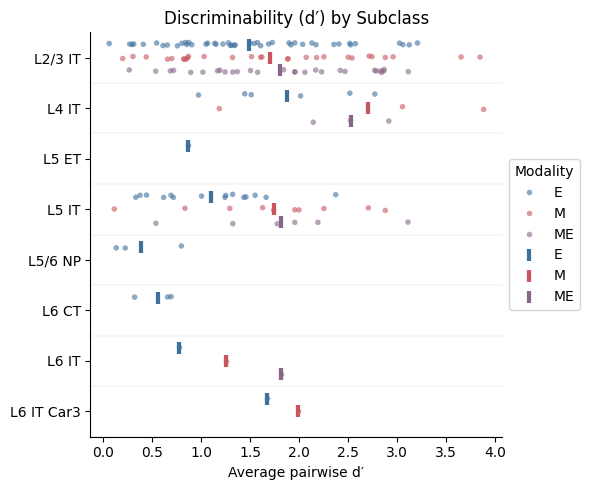

Saved: multimodal_dprime_pairwise_avg_by_subclass.pdf


In [13]:
# Combine E, M, ME data for subclass comparison
e_subclass_long['modality'] = 'E'
m_subclass_long['modality'] = 'M'
me_subclass_long['modality'] = 'ME'

data_subclass = pd.concat([e_subclass_long, m_subclass_long, me_subclass_long])
data_subclass.to_csv(OUT_DIR / 'multimodal_dprime_pairwise_avg_by_subclass.csv', index=False)

# Create plot
fig, ax = plt.subplots(figsize=(6, 5))

sns.stripplot(
    data=data_subclass, x='dprime', y='subclass_label', hue='modality',
    size=4, jitter=True, alpha=0.6, dodge=True, palette=modality_color_dict
)
sns.pointplot(
    data=data_subclass, x='dprime', y='subclass_label', hue='modality',
    dodge=0.5, join=False, errorbar=None, markers='|', scale=1.5, palette=modality_color_dict
)

# Add horizontal separators
for i in range(len(data_subclass['subclass_label'].unique())):
    ax.axhline(y=i + 0.5, color='gray', lw=0.25, alpha=0.4)

sns.despine(top=True, right=True)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='Modality')
plt.xlabel("Average pairwise d′")
plt.ylabel("")
plt.title("Discriminability (d′) by Subclass")
plt.tight_layout()
plt.savefig(OUT_DIR / 'multimodal_dprime_pairwise_avg_by_subclass.pdf', dpi=600)
plt.show()

print("Saved: multimodal_dprime_pairwise_avg_by_subclass.pdf")